# 01 - Exploratory Data Analysis (EDA)
**Fair Mortgage Approval Decisions - ADS End-Term Project, Group 8**

**BADIR stage:** *Data -> Insights*. This notebook describes the single-source-of-truth (SSOT) table and looks for patterns that bear on hypotheses H1-H7.

> **EDA is descriptive.** Gaps shown here are *raw* (unadjusted) and are **not** tests and **not** causal. Formal tests, matching and the model come in the next notebooks.

**Stakeholder:** the credit-risk team of a US home-loan lender. **Decision:** which approval rule should the bank follow so it is safe *and* fair?

| Source | Role | Joined on |
|---|---|---|
| HMDA (CFPB/FFIEC), 2018-2023 | base table: one row per application | - |
| Census ACS 5-year | tract income, house value, poverty, unemployment | census tract + ACS year |
| FRED | 30-year mortgage rate, CPI (inflation) | year |

Scope kept: home-purchase, first-lien, owner-occupied applications that were **originated (approved) or denied**. A fixed 5% random sample per state-year (seed 42 + year). Details: `reports/data_quality_report.md`.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# ---- chart style (one place, so every figure looks the same) ----------------
BLUE, ORANGE = "#2F5A45", "#8B2635"          # blue = default, orange = the thing we highlight
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
from matplotlib import font_manager as _fm
for _p in Path.home().glob("AppData/Local/Microsoft/Windows/Fonts/Merriweather-*.ttf"):
    _fm.fontManager.addfont(str(_p))
plt.rcParams.update({"font.family": ["Merriweather", "DejaVu Serif", "serif"], 
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
})

def finish(ax, title, subtitle=None, name=None):
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold", color=INK, pad=22 if subtitle else 8)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9, color=MUTED, va="bottom")
    plt.tight_layout()
    if name:
        plt.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

df = pd.read_parquet(ROOT / "data" / "processed" / "ssot.parquet")
print(f"SSOT: {df.shape[0]:,} rows x {df.shape[1]} columns")

SSOT: 1,320,227 rows x 99 columns


## 1. Data audit: size, coverage, quality

In [2]:
print("Rows per year and denial rate")
yr = df.groupby("year").agg(rows=("denied", "size"), denial_rate=("denied", "mean"),
                            mortgage_rate=("fred_mortgage_rate_30y", "first")).round(3)
display(yr)

print("\nShare of rows matched to ACS tract data:", f"{df['tract_matched_acs'].mean():.1%}")
print("Rows with an exact (not range) DTI value:", f"{df['dti_is_exact'].mean():.1%}",
      "| DTI missing:", f"{df['dti_missing'].mean():.1%}")

Rows per year and denial rate


,rows,denial_rate,mortgage_rate
year,,,
2018,213875,0.132,4.545
2019,219896,0.123,3.936
2020,242691,0.125,3.112
2021,257792,0.119,2.958
2022,213413,0.138,5.344
2023,172560,0.153,6.807



Share of rows matched to ACS tract data: 98.3%
Rows with an exact (not range) DTI value: 48.2% | DTI missing: 3.2%


derived_race == 'Race Not Available': 13.0%


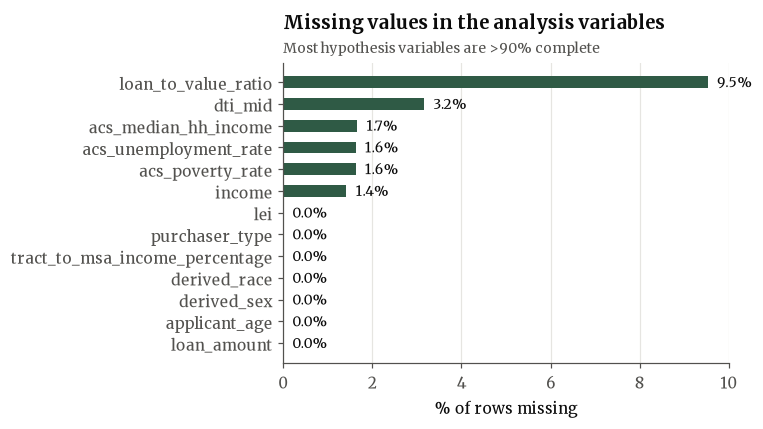

In [3]:
# Missing values for the variables the hypotheses actually use
key = ["dti_mid", "loan_to_value_ratio", "income", "loan_amount", "derived_race", "derived_sex", "applicant_age",
       "tract_to_msa_income_percentage", "acs_median_hh_income", "acs_poverty_rate", "acs_unemployment_rate",
       "purchaser_type", "lei"]
miss = df[key].isna().mean().sort_values()
# 'Race Not Available' is a coded value, not NaN, so count it separately
print("derived_race == 'Race Not Available':", f"{(df['derived_race'] == 'Race Not Available').mean():.1%}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(miss.index, miss.values * 100, color=BLUE, height=0.55)
for i, v in enumerate(miss.values * 100):
    ax.text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=9, color=INK)
ax.set_xlabel("% of rows missing"); ax.grid(axis="y", visible=False)
finish(ax, "Missing values in the analysis variables", "Most hypothesis variables are >90% complete", "01_missing")

## 2. Outcome: how often are applications denied?

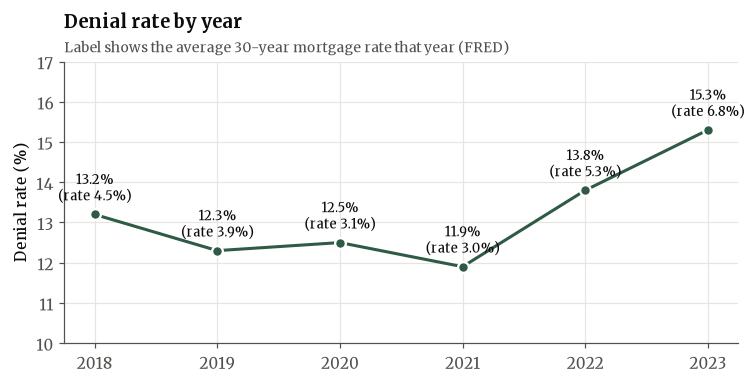

0.97 <- correlation of 6 yearly points: far too few to conclude anything (H4).


In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(yr.index, yr.denial_rate * 100, color=BLUE, lw=2, marker="o", ms=7, mfc=BLUE, mec="white", mew=1.5)
for x, y, r in zip(yr.index, yr.denial_rate * 100, yr.mortgage_rate):
    ax.text(x, y + 0.35, f"{y:.1f}%\n(rate {r:.1f}%)", ha="center", fontsize=8.5, color=INK)
ax.set_ylim(10, 17); ax.set_ylabel("Denial rate (%)"); ax.set_xticks(yr.index)
finish(ax, "Denial rate by year", "Label shows the average 30-year mortgage rate that year (FRED)", "02_denial_by_year")

print(yr.corr().round(2).loc["denial_rate", "mortgage_rate"], "<- correlation of 6 yearly points: far too few to conclude anything (H4).")

### Denial reasons (only recorded for denied applications)
HMDA codes: 1 debt-to-income, 2 employment history, 3 credit history, 4 collateral, 5 insufficient cash, 6 unverifiable information, 7 credit application incomplete, 8 mortgage insurance denied, 9 other.

Denied rows with a primary reason recorded: 98.5%


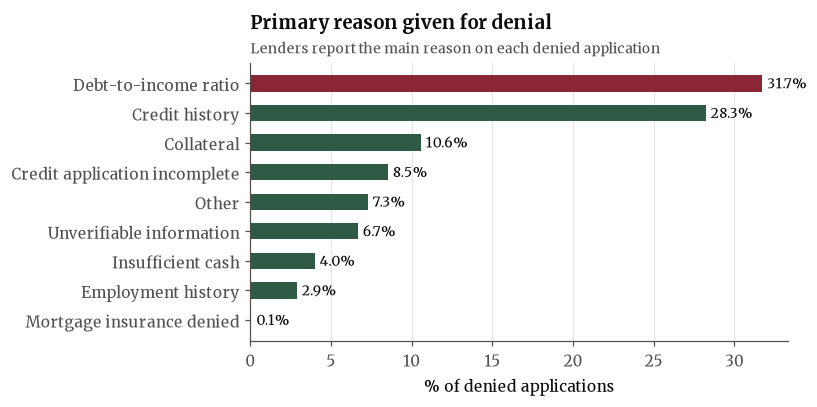

In [5]:
reason_names = {"1": "Debt-to-income ratio", "2": "Employment history", "3": "Credit history", "4": "Collateral",
                "5": "Insufficient cash", "6": "Unverifiable information", "7": "Credit application incomplete",
                "8": "Mortgage insurance denied", "9": "Other"}
den = df[df["denied"] == 1]
rs = den["denial_reason-1"].map(reason_names).value_counts(normalize=True).sort_values()
print("Denied rows with a primary reason recorded:", f"{den['denial_reason-1'].isin(reason_names).mean():.1%}")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(rs.index, rs.values * 100, color=[ORANGE if i == rs.index[-1] else BLUE for i in rs.index], height=0.55)
for i, v in enumerate(rs.values * 100):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("% of denied applications"); ax.grid(axis="y", visible=False)
finish(ax, "Primary reason given for denial", "Lenders report the main reason on each denied application", "03_denial_reasons")

## 3. H1 - Does the denial rate jump above DTI 43%?
HMDA gives **exact** DTI for 36-49% and **ranges** elsewhere (e.g. `30%-<36%`). Bars below use HMDA's own labels, ordered by the DTI value (`dti_mid`). Orange = above 43%.

 dti_mid debt_to_income_ratio  rate      n
    15.0                 <20% 0.157  66911
    25.0             20%-<30% 0.080 208484
    33.0             30%-<36% 0.074 208578
    36.0                   36 0.073  40667
    37.0                   37 0.073  42393
    38.0                   38 0.075  44572
    39.0                   39 0.077  46845
    40.0                   40 0.077  48482
    41.0                   41 0.078  49421
    42.0                   42 0.076  53011
    43.0                   43 0.082  48860
    44.0                   44 0.081  53953
    45.0                   45 0.090  41209
    46.0                   46 0.100  38344
    47.0                   47 0.099  38323
    48.0                   48 0.104  40411
    49.0                   49 0.091  49552
    55.0              50%-60% 0.239 115283
    65.0                 >60% 0.877  43054


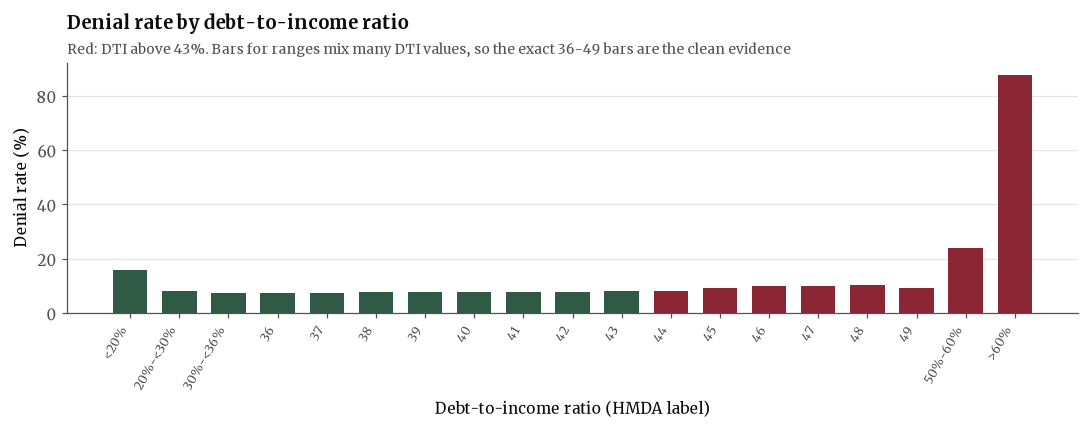

In [6]:
d = df.dropna(subset=["dti_mid"]).copy()
g = (d.groupby(["dti_mid", "debt_to_income_ratio"]).agg(rate=("denied", "mean"), n=("denied", "size"))
       .reset_index().sort_values("dti_mid"))
print(g.assign(rate=g.rate.round(3)).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4))
colors = [ORANGE if m > 43 else BLUE for m in g.dti_mid]
ax.bar(range(len(g)), g.rate * 100, color=colors, width=0.7)
ax.set_xticks(range(len(g))); ax.set_xticklabels(g.debt_to_income_ratio, rotation=60, ha="right", fontsize=8)
ax.set_ylabel("Denial rate (%)"); ax.grid(axis="x", visible=False)
ax.set_xlabel("Debt-to-income ratio (HMDA label)")
finish(ax, "Denial rate by debt-to-income ratio", "Red: DTI above 43%. Bars for ranges mix many DTI values, so the exact 36-49 bars are the clean evidence", "04_denial_by_dti")

In [7]:
# Robustness: is the pattern the same when we use ONLY rows with exact DTI values (36-49)?
e = df[df["dti_is_exact"]]
print("Rows with exact DTI:", f"{len(e):,}")
print(e.groupby(e["dti_mid"].clip(36, 49)).denied.mean().round(3).to_string())
print("\nDenial rate: exact-DTI rows =", f"{e.denied.mean():.3f}", "| range-DTI rows =", f"{df[~df.dti_is_exact & df.dti_mid.notna()].denied.mean():.3f}",
      "(ranges include the very high DTIs, so this is not like-for-like)")

Rows with exact DTI: 636,043
dti_mid
36.0    0.073
37.0    0.073
38.0    0.075
39.0    0.077
40.0    0.077
41.0    0.078
42.0    0.076
43.0    0.082
44.0    0.081
45.0    0.090
46.0    0.100
47.0    0.099
48.0    0.104
49.0    0.091



Denial rate: exact-DTI rows = 0.083 | range-DTI rows = 0.168 (ranges include the very high DTIs, so this is not like-for-like)


## 4. H2 / H6 - Are there denial gaps by race? (raw gaps, *before* adjusting)
`derived_race` is HMDA's single-category race summary. 'Race Not Available' is kept and shown, never silently dropped. Small groups are merged into 'Other / 2+ races' so no bar rests on a tiny sample.

                           n  rate_pct
race_grp                              
Asian                  80501      10.3
Joint (mixed couple)   31519      11.0
White                 911425      11.3
Race not available    171087      16.0
Other / 2+ races       13356      23.7
Black                 112339      23.8


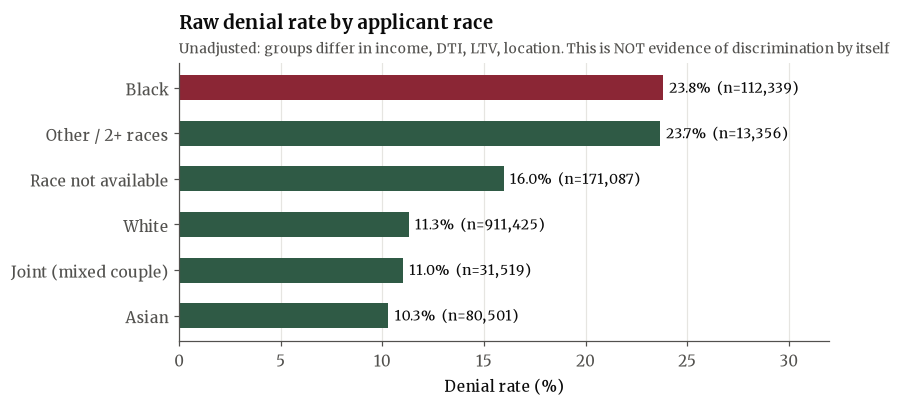

In [8]:
race_map = {"White": "White", "Black or African American": "Black", "Asian": "Asian", "Joint": "Joint (mixed couple)",
            "Race Not Available": "Race not available",
            "American Indian or Alaska Native": "Other / 2+ races", "Native Hawaiian or Other Pacific Islander": "Other / 2+ races",
            "2 or more minority races": "Other / 2+ races", "Free Form Text Only": "Other / 2+ races"}
df["race_grp"] = df["derived_race"].map(race_map)
r = df.groupby("race_grp").agg(rate=("denied", "mean"), n=("denied", "size")).sort_values("rate")
r["rate_pct"] = (r.rate * 100).round(1)
print(r[["n", "rate_pct"]].to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(r.index, r.rate * 100, color=[ORANGE if i == "Black" else BLUE for i in r.index], height=0.55)
for i, (v, n) in enumerate(zip(r.rate * 100, r.n)):
    ax.text(v + 0.3, i, f"{v:.1f}%  (n={n:,})", va="center", fontsize=9)
ax.set_xlabel("Denial rate (%)"); ax.grid(axis="y", visible=False); ax.set_xlim(0, 32)
finish(ax, "Raw denial rate by applicant race", "Unadjusted: groups differ in income, DTI, LTV, location. This is NOT evidence of discrimination by itself", "05_denial_by_race")

dti_group race_grp  rate      n
 DTI < 36    Asian 0.063  29426
 DTI < 36    Black 0.201  26987
 DTI < 36    White 0.077 350763
DTI 36-43    Asian 0.060  24167
DTI 36-43    Black 0.136  31240
DTI 36-43    White 0.067 259042
 DTI > 43    Asian 0.188  24708
 DTI > 43    Black 0.301  51425
 DTI > 43    White 0.190 269437


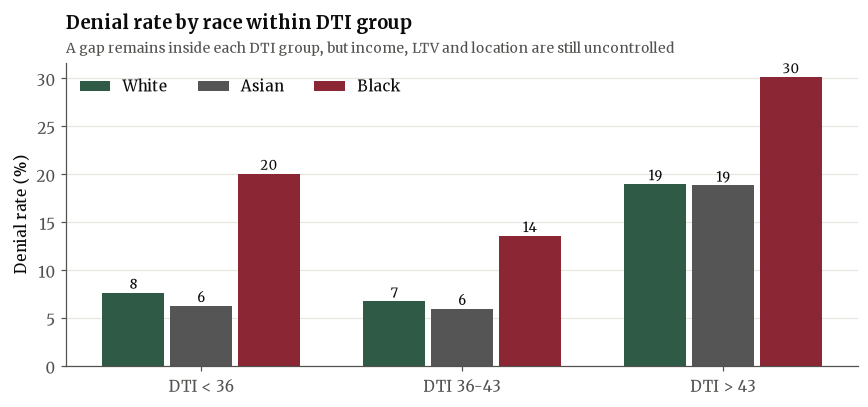

In [9]:
# A first, crude look at whether gaps survive when applicants look similar on DTI.
# (H2 properly needs matching / regression - next notebook.)
d = df[df.race_grp.isin(["White", "Black", "Asian"]) & df.dti_mid.notna()].copy()
d["dti_group"] = pd.cut(d.dti_mid, [0, 35.99, 43, 100], labels=["DTI < 36", "DTI 36-43", "DTI > 43"])
t = d.groupby(["dti_group", "race_grp"], observed=True).agg(rate=("denied", "mean"), n=("denied", "size")).reset_index()
print(t.assign(rate=t.rate.round(3)).to_string(index=False))

pv = t.pivot(index="dti_group", columns="race_grp", values="rate")[["White", "Asian", "Black"]] * 100
fig, ax = plt.subplots(figsize=(8, 3.8))
w = 0.26
for k, (grp, col) in enumerate(zip(["White", "Asian", "Black"], [BLUE, "#555555", ORANGE])):
    xs = np.arange(len(pv)) + (k - 1) * w
    ax.bar(xs, pv[grp], width=w * 0.92, color=col, label=grp)
    for x, v in zip(xs, pv[grp]):
        ax.text(x, v + 0.4, f"{v:.0f}", ha="center", fontsize=8.5)
ax.set_xticks(range(len(pv))); ax.set_xticklabels(pv.index); ax.set_ylabel("Denial rate (%)")
ax.grid(axis="x", visible=False); ax.legend(frameon=False, ncol=3, loc="upper left")
finish(ax, "Denial rate by race within DTI group", "A gap remains inside each DTI group, but income, LTV and location are still uncontrolled", "06_race_within_dti")

## 5. H3 - Low-income neighbourhoods
FFIEC tract income levels use the tract's median family income as a % of its metro area: low < 50%, moderate 50-79%, middle 80-119%, upper >= 120%.

                   rate       n
tract_level                    
Low (<50%)         18.6   31407
Moderate (50-79%)  16.1  206130
Middle (80-119%)   12.8  589265
Upper (120%+)       8.8  473015


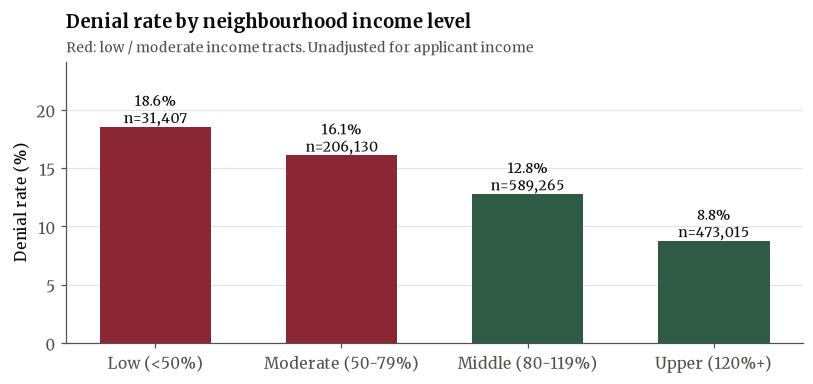

In [10]:
d = df.dropna(subset=["tract_to_msa_income_percentage"]).copy()
d = d[d.tract_to_msa_income_percentage > 0]                      # 0 = tract income unavailable in HMDA
d["tract_level"] = pd.cut(d.tract_to_msa_income_percentage, [0, 49.99, 79.99, 119.99, 1000],
                          labels=["Low (<50%)", "Moderate (50-79%)", "Middle (80-119%)", "Upper (120%+)"])
t = d.groupby("tract_level", observed=True).agg(rate=("denied", "mean"), n=("denied", "size"))
print(t.assign(rate=(t.rate * 100).round(1)).to_string())

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.bar(t.index.astype(str), t.rate * 100, color=[ORANGE, ORANGE, BLUE, BLUE], width=0.6)
for i, (v, n) in enumerate(zip(t.rate * 100, t.n)):
    ax.text(i, v + 0.3, f"{v:.1f}%\nn={n:,}", ha="center", fontsize=9)
ax.set_ylabel("Denial rate (%)"); ax.set_ylim(0, t.rate.max() * 100 * 1.3); ax.grid(axis="x", visible=False)
finish(ax, "Denial rate by neighbourhood income level", "Red: low / moderate income tracts. Unadjusted for applicant income", "07_denial_by_tract_income")

## 6. Applicant and loan characteristics (features for H5)

         rate       n
ltv_bin              
<=60      7.7   84573
60-70     8.0   54361
70-80     6.7  271015
80-90     9.1  158762
90-95     8.9  206274
95-97    11.3  225452
97-100   11.3  138067
>100     18.4   55910


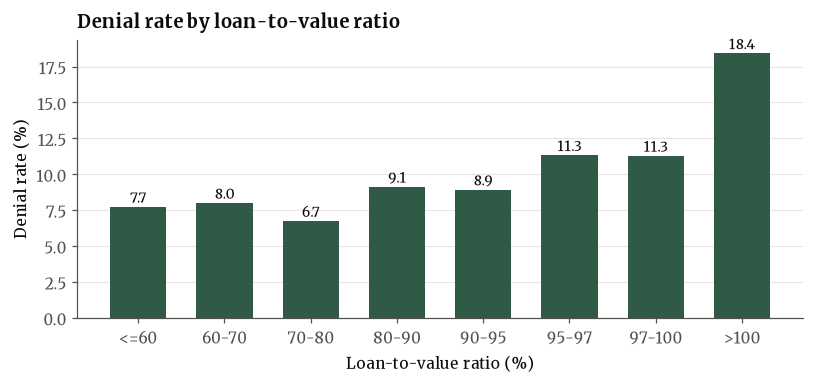

In [11]:
d = df.dropna(subset=["loan_to_value_ratio"]).copy()
d["ltv_bin"] = pd.cut(d.loan_to_value_ratio, [0, 60, 70, 80, 90, 95, 97, 100, 200],
                      labels=["<=60", "60-70", "70-80", "80-90", "90-95", "95-97", "97-100", ">100"])
t = d.groupby("ltv_bin", observed=True).agg(rate=("denied", "mean"), n=("denied", "size"))
print(t.assign(rate=(t.rate * 100).round(1)).to_string())

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.bar(t.index.astype(str), t.rate * 100, color=BLUE, width=0.65)
for i, v in enumerate(t.rate * 100):
    ax.text(i, v + 0.3, f"{v:.1f}", ha="center", fontsize=9)
ax.set_xlabel("Loan-to-value ratio (%)"); ax.set_ylabel("Denial rate (%)"); ax.grid(axis="x", visible=False)
finish(ax, "Denial rate by loan-to-value ratio", None, "08_denial_by_ltv")

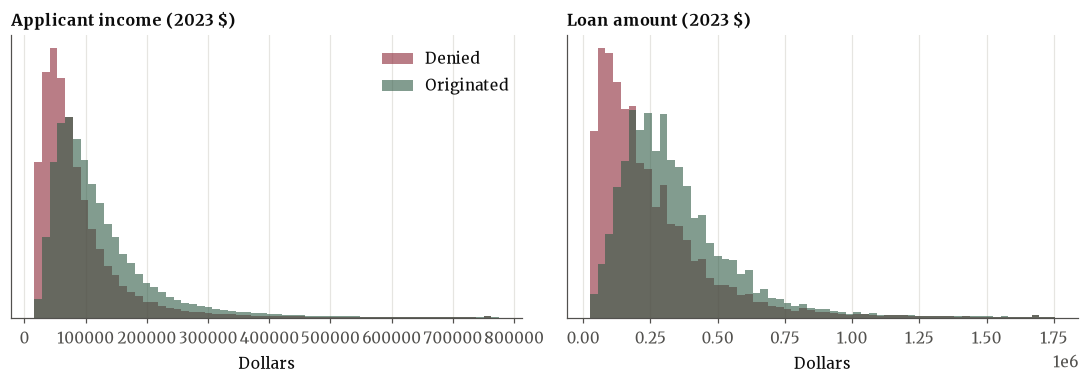

       income_real  loan_amount_real  loan_to_income
count    1301476.0         1320227.0       1301476.0
mean      124427.4          344566.8             3.2
std       105947.2          253488.2             1.7
min        16000.0           25000.0             0.0
25%        63564.2          185538.5             2.1
50%        95346.3          286741.3             3.0
75%       146599.2          423111.6             3.9
max       914960.3         2044705.6           105.3


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, col, title in [(axes[0], "income_real", "Applicant income (2023 $)"), (axes[1], "loan_amount_real", "Loan amount (2023 $)")]:
    x = df[col].dropna()
    x = x[(x > 0) & (x < x.quantile(0.995))]
    ax.hist([x[df.loc[x.index, "denied"] == 0], x[df.loc[x.index, "denied"] == 1]], bins=60, density=True,
            color=[BLUE, ORANGE], label=["Originated", "Denied"], histtype="stepfilled", alpha=0.6)
    ax.set_title(title, loc="left", fontsize=10.5, fontweight="bold"); ax.set_yticks([]); ax.set_xlabel("Dollars")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / "09_income_loan_distributions.png", bbox_inches="tight"); plt.show()
print(df[["income_real", "loan_amount_real", "loan_to_income"]].describe().round(1).to_string())

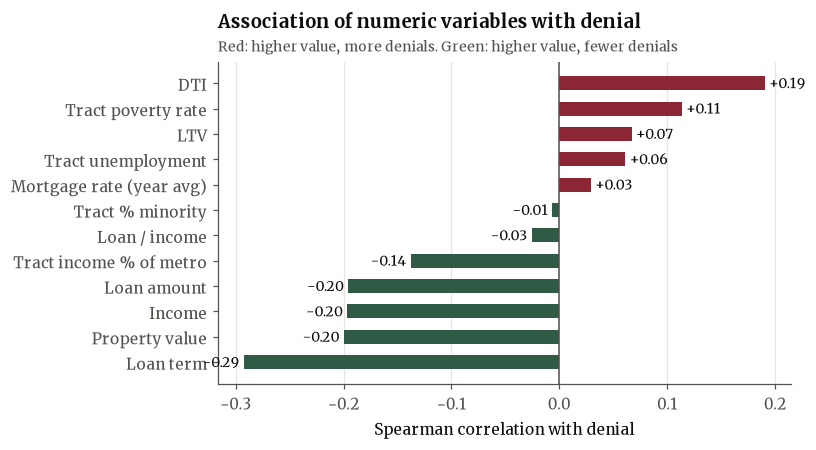

In [13]:
# Which numeric variables move with denial? (correlation = association only)
cols = {"dti_mid": "DTI", "loan_to_value_ratio": "LTV", "loan_to_income": "Loan / income", "income_real": "Income",
        "loan_amount_real": "Loan amount", "property_value_real": "Property value", "acs_poverty_rate": "Tract poverty rate",
        "acs_unemployment_rate": "Tract unemployment", "tract_minority_population_percent": "Tract % minority",
        "tract_to_msa_income_percentage": "Tract income % of metro", "fred_mortgage_rate_30y": "Mortgage rate (year avg)",
        "loan_term": "Loan term"}
c = df[list(cols)].corrwith(df["denied"], method="spearman").rename(index=cols).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(c.index, c.values, color=[ORANGE if v > 0 else BLUE for v in c.values], height=0.55)
for i, v in enumerate(c.values):
    ax.text(v + (0.004 if v >= 0 else -0.004), i, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.axvline(0, color=MUTED, lw=1); ax.set_xlabel("Spearman correlation with denial"); ax.grid(axis="y", visible=False)
finish(ax, "Association of numeric variables with denial", "Red: higher value, more denials. Green: higher value, fewer denials", "10_correlations")

## 7. Leakage check - columns that must NOT be used to predict denial (H5)
Some columns exist only after a loan is approved and priced. A model that sees them would 'predict' denial by noticing the column is empty. Below: share of rows that are missing, split by outcome.

In [14]:
leaky = ["interest_rate", "rate_spread", "total_loan_costs", "origination_charges", "discount_points",
         "lender_credits", "total_points_and_fees", "intro_rate_period", "prepayment_penalty_term"]
t = df.groupby("denied")[leaky].apply(lambda g: g.isna().mean()).T.round(3)
t.columns = ["missing among originated", "missing among denied"]
display(t)
print("Columns with a big gap are leakage -> excluded from the model. Also excluded: action_taken, denial_reason-1, purchaser_type, hoepa_status.")

,missing among originated,missing among denied
interest_rate,0.022,1.000
rate_spread,0.035,1.000
total_loan_costs,0.054,1.000
origination_charges,0.047,1.000
discount_points,0.624,1.000
lender_credits,0.623,1.000
total_points_and_fees,0.985,1.000
intro_rate_period,0.944,0.939
prepayment_penalty_term,0.999,0.994


Columns with a big gap are leakage -> excluded from the model. Also excluded: action_taken, denial_reason-1, purchaser_type, hoepa_status.


## 8. Lender type (H7) - status
The pre-submission planned to use the HMDA Reporter Panel to label lenders as bank / credit union / non-bank. That file is **not yet downloaded**. What we already have: `lei` (lender ID), so we can at least see how concentrated lending is.

In [15]:
l = df.groupby("lei").agg(n=("denied", "size"), rate=("denied", "mean")).sort_values("n", ascending=False)
print("Distinct lenders (LEI):", f"{len(l):,}")
print("Share of applications held by the top 20 lenders:", f"{l.n.head(20).sum() / l.n.sum():.1%}")
print("Lenders with >= 500 sampled applications:", int((l.n >= 500).sum()))
print("Denial rate spread across those lenders (10th-90th percentile):",
      l[l.n >= 500].rate.quantile([0.1, 0.9]).round(3).tolist())

Distinct lenders (LEI): 5,315
Share of applications held by the top 20 lenders: 33.5%
Lenders with >= 500 sampled applications: 390
Denial rate spread across those lenders (10th-90th percentile): [0.026, 0.182]


## 9. What the EDA suggests (descriptive only - formal tests come next)

| Hypothesis | What we see | Next step |
|---|---|---|
| **H1** DTI > 43% | Exact-DTI bars rise *gradually* (7.3% at 36 -> 8.2% at 43 -> ~10% at 46-48); there is no obvious sharp jump at 43. The big jumps are at 50-60% (23.9%) and >60% (87.7%). | Regression discontinuity at 43 using the exact 36-49 values |
| **H2** race gap | Raw denial rate: Black 23.8% vs White 11.3%. The gap remains inside each DTI group (e.g. 20.1% vs 7.7% for DTI < 36). Income, LTV and location are not yet controlled. | Chi-square, then propensity-score matching / regression with controls |
| **H3** low-income areas | Denial falls steadily with tract income: 18.6% (low) -> 8.8% (upper). Not yet adjusted for applicant income. | t-test / regression with applicant controls |
| **H4** interest rates | Yearly denial rate and average mortgage rate move together (r = 0.97) but that is only 6 points and the rate is national. | Report as inconclusive unless supported by a tighter design |
| **H5** model | LTV, DTI, tract income, loan/income all associate with denial. Columns such as `interest_rate` exist only for approved loans -> **excluded as leakage**. | Gradient boosting + SHAP on non-leaky features |
| **H6** error gaps | Needs a model first. | Compare error rates by group |
| **H7** lender type | Reporter Panel not yet used; `lei` is available (5,315 lenders). | Decide data source for lender type |

### Data issues found (to handle before modelling)
- **Outliers (fixed in the build):** raw income reached ~$846M and loan/income 1,755. `income`, `loan_amount`, `property_value` are kept as recorded; winsorized copies (0.5th-99.5th percentile) feed all `*_real` and loan-to-income columns. 1.8% of rows are flagged `outlier_flag`.
- **DTI ranges:** about half of rows have a range instead of an exact DTI; results will be checked on exact-DTI rows only.
- **'<20%' DTI has a 15.7% denial rate** (higher than 20-36%). Checked: it holds in every year, and 47% of those denials cite credit history, so it is real in the data, not a build error (likely applicants with thin credit or other problems; we cannot see credit scores).
- **'Race not available'** is 13% of rows and has a 16% denial rate - kept as its own group, never dropped.